In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv


In [2]:
df = pd.read_csv("/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv")
temp = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv')
df = pd.merge(df, temp, on='order_id', how='outer')
temp = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv')
df = pd.merge(df, temp, on='order_id', how='outer')
df

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118429,fffc94f6ce00a00581880bf54a75a037,1.0,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,1.0,boleto,1.0,343.40,b51593916b4b8e0d6f66f2ae24f2673d,delivered,2018-04-23 13:57:06,2018-04-25 04:11:01,2018-04-25 12:09:00,2018-05-10 22:56:40,2018-05-18 00:00:00
118430,fffcd46ef2263f404302a634eb57f7eb,1.0,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,1.0,boleto,1.0,386.53,84c5d4fbaf120aae381fad077416eaa0,delivered,2018-07-14 10:26:46,2018-07-17 04:31:48,2018-07-17 08:05:00,2018-07-23 20:31:55,2018-08-01 00:00:00
118431,fffce4705a9662cd70adb13d4a31832d,1.0,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,1.0,credit_card,3.0,116.85,29309aa813182aaddc9b259e31b870e6,delivered,2017-10-23 17:07:56,2017-10-24 17:14:25,2017-10-26 15:13:14,2017-10-28 12:22:22,2017-11-10 00:00:00
118432,fffe18544ffabc95dfada21779c9644f,1.0,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,1.0,credit_card,3.0,64.71,b5e6afd5a41800fdf401e0272ca74655,delivered,2017-08-14 23:02:59,2017-08-15 00:04:32,2017-08-15 19:02:53,2017-08-16 21:59:40,2017-08-25 00:00:00


In [3]:
df = df.drop(columns = ['order_delivered_carrier_date'])
df

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17 00:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118429,fffc94f6ce00a00581880bf54a75a037,1.0,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,1.0,boleto,1.0,343.40,b51593916b4b8e0d6f66f2ae24f2673d,delivered,2018-04-23 13:57:06,2018-04-25 04:11:01,2018-05-10 22:56:40,2018-05-18 00:00:00
118430,fffcd46ef2263f404302a634eb57f7eb,1.0,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,1.0,boleto,1.0,386.53,84c5d4fbaf120aae381fad077416eaa0,delivered,2018-07-14 10:26:46,2018-07-17 04:31:48,2018-07-23 20:31:55,2018-08-01 00:00:00
118431,fffce4705a9662cd70adb13d4a31832d,1.0,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,1.0,credit_card,3.0,116.85,29309aa813182aaddc9b259e31b870e6,delivered,2017-10-23 17:07:56,2017-10-24 17:14:25,2017-10-28 12:22:22,2017-11-10 00:00:00
118432,fffe18544ffabc95dfada21779c9644f,1.0,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,1.0,credit_card,3.0,64.71,b5e6afd5a41800fdf401e0272ca74655,delivered,2017-08-14 23:02:59,2017-08-15 00:04:32,2017-08-16 21:59:40,2017-08-25 00:00:00


In [4]:
df = df[df['order_status'] == 'delivered']
df.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17 00:00:00
5,00048cc3ae777c65dbb7d2a0634bc1ea,1.0,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,1.0,boleto,1.0,34.59,816cbea969fe5b689b39cfc97a506742,delivered,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-22 13:44:35,2017-06-06 00:00:00
6,00054e8431b9d7675808bcb819fb4a32,1.0,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,1.0,credit_card,1.0,31.75,32e2e6ab09e778d99bf2e0ecd4898718,delivered,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-18 22:03:38,2018-01-04 00:00:00
7,000576fe39319847cbb9d288c5617fa6,1.0,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,1.0,credit_card,10.0,880.75,9ed5e522dd9dd85b4af4a077526d8117,delivered,2018-07-04 12:08:27,2018-07-05 16:35:48,2018-07-09 14:04:07,2018-07-25 00:00:00
8,0005a1a1728c9d785b8e2b08b904576c,1.0,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,1.0,credit_card,3.0,157.60,16150771dfd4776261284213b89c304e,delivered,2018-03-19 18:40:33,2018-03-20 18:35:21,2018-03-29 18:17:31,2018-03-29 00:00:00
9,0005f50442cb953dcd1d21e1fb923495,1.0,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,1.0,credit_card,1.0,65.39,351d3cb2cee3c7fd0af6616c82df21d3,delivered,2018-07-02 13:59:39,2018-07-02 14:10:56,2018-07-04 17:28:31,2018-07-23 00:00:00


In [5]:
df = df.dropna(subset=['order_delivered_customer_date', 'order_estimated_delivery_date'])
df.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17 00:00:00
5,00048cc3ae777c65dbb7d2a0634bc1ea,1.0,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,1.0,boleto,1.0,34.59,816cbea969fe5b689b39cfc97a506742,delivered,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-22 13:44:35,2017-06-06 00:00:00
6,00054e8431b9d7675808bcb819fb4a32,1.0,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,1.0,credit_card,1.0,31.75,32e2e6ab09e778d99bf2e0ecd4898718,delivered,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-18 22:03:38,2018-01-04 00:00:00
7,000576fe39319847cbb9d288c5617fa6,1.0,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,1.0,credit_card,10.0,880.75,9ed5e522dd9dd85b4af4a077526d8117,delivered,2018-07-04 12:08:27,2018-07-05 16:35:48,2018-07-09 14:04:07,2018-07-25 00:00:00
8,0005a1a1728c9d785b8e2b08b904576c,1.0,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,1.0,credit_card,3.0,157.60,16150771dfd4776261284213b89c304e,delivered,2018-03-19 18:40:33,2018-03-20 18:35:21,2018-03-29 18:17:31,2018-03-29 00:00:00
9,0005f50442cb953dcd1d21e1fb923495,1.0,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,1.0,credit_card,1.0,65.39,351d3cb2cee3c7fd0af6616c82df21d3,delivered,2018-07-02 13:59:39,2018-07-02 14:10:56,2018-07-04 17:28:31,2018-07-23 00:00:00


In [6]:
df = df.drop(columns = ['order_status'])
df.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29 00:00:00
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15 00:00:00
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05 00:00:00
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20 00:00:00
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17 00:00:00
5,00048cc3ae777c65dbb7d2a0634bc1ea,1.0,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,1.0,boleto,1.0,34.59,816cbea969fe5b689b39cfc97a506742,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-22 13:44:35,2017-06-06 00:00:00
6,00054e8431b9d7675808bcb819fb4a32,1.0,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,1.0,credit_card,1.0,31.75,32e2e6ab09e778d99bf2e0ecd4898718,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-18 22:03:38,2018-01-04 00:00:00
7,000576fe39319847cbb9d288c5617fa6,1.0,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,1.0,credit_card,10.0,880.75,9ed5e522dd9dd85b4af4a077526d8117,2018-07-04 12:08:27,2018-07-05 16:35:48,2018-07-09 14:04:07,2018-07-25 00:00:00
8,0005a1a1728c9d785b8e2b08b904576c,1.0,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,1.0,credit_card,3.0,157.60,16150771dfd4776261284213b89c304e,2018-03-19 18:40:33,2018-03-20 18:35:21,2018-03-29 18:17:31,2018-03-29 00:00:00
9,0005f50442cb953dcd1d21e1fb923495,1.0,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,1.0,credit_card,1.0,65.39,351d3cb2cee3c7fd0af6616c82df21d3,2018-07-02 13:59:39,2018-07-02 14:10:56,2018-07-04 17:28:31,2018-07-23 00:00:00


In [7]:
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])
df['label'] = df['order_delivered_customer_date'] > df['order_estimated_delivery_date']
df.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,label
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29,False
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15,False
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05,False
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17,False
5,00048cc3ae777c65dbb7d2a0634bc1ea,1.0,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,1.0,boleto,1.0,34.59,816cbea969fe5b689b39cfc97a506742,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-22 13:44:35,2017-06-06,False
6,00054e8431b9d7675808bcb819fb4a32,1.0,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,1.0,credit_card,1.0,31.75,32e2e6ab09e778d99bf2e0ecd4898718,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-18 22:03:38,2018-01-04,False
7,000576fe39319847cbb9d288c5617fa6,1.0,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,1.0,credit_card,10.0,880.75,9ed5e522dd9dd85b4af4a077526d8117,2018-07-04 12:08:27,2018-07-05 16:35:48,2018-07-09 14:04:07,2018-07-25,False
8,0005a1a1728c9d785b8e2b08b904576c,1.0,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,1.0,credit_card,3.0,157.60,16150771dfd4776261284213b89c304e,2018-03-19 18:40:33,2018-03-20 18:35:21,2018-03-29 18:17:31,2018-03-29,True
9,0005f50442cb953dcd1d21e1fb923495,1.0,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,1.0,credit_card,1.0,65.39,351d3cb2cee3c7fd0af6616c82df21d3,2018-07-02 13:59:39,2018-07-02 14:10:56,2018-07-04 17:28:31,2018-07-23,False


In [8]:
df.head(10)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,label
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-20 23:43:48,2017-09-29,False
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-12 16:04:24,2017-05-15,False
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-22 13:19:16,2018-02-05,False
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-14 13:32:39,2018-08-20,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-03-01 16:42:31,2017-03-17,False
5,00048cc3ae777c65dbb7d2a0634bc1ea,1.0,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69,1.0,boleto,1.0,34.59,816cbea969fe5b689b39cfc97a506742,2017-05-15 21:42:34,2017-05-17 03:55:27,2017-05-22 13:44:35,2017-06-06,False
6,00054e8431b9d7675808bcb819fb4a32,1.0,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85,1.0,credit_card,1.0,31.75,32e2e6ab09e778d99bf2e0ecd4898718,2017-12-10 11:53:48,2017-12-10 12:10:31,2017-12-18 22:03:38,2018-01-04,False
7,000576fe39319847cbb9d288c5617fa6,1.0,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75,1.0,credit_card,10.0,880.75,9ed5e522dd9dd85b4af4a077526d8117,2018-07-04 12:08:27,2018-07-05 16:35:48,2018-07-09 14:04:07,2018-07-25,False
8,0005a1a1728c9d785b8e2b08b904576c,1.0,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65,1.0,credit_card,3.0,157.60,16150771dfd4776261284213b89c304e,2018-03-19 18:40:33,2018-03-20 18:35:21,2018-03-29 18:17:31,2018-03-29,True
9,0005f50442cb953dcd1d21e1fb923495,1.0,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40,1.0,credit_card,1.0,65.39,351d3cb2cee3c7fd0af6616c82df21d3,2018-07-02 13:59:39,2018-07-02 14:10:56,2018-07-04 17:28:31,2018-07-23,False


In [9]:
df = df.drop(columns = ['order_delivered_customer_date', 'order_estimated_delivery_date'])
df

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,payment_sequential,payment_type,payment_installments,payment_value,customer_id,order_purchase_timestamp,order_approved_at,label
0,00010242fe8c5a6d1ba2dd792cb16214,1.0,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,1.0,credit_card,2.0,72.19,3ce436f183e68e07877b285a838db11a,2017-09-13 08:59:02,2017-09-13 09:45:35,False
1,00018f77f2f0320c557190d7a144bdd3,1.0,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,1.0,credit_card,3.0,259.83,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26 10:53:06,2017-04-26 11:05:13,False
2,000229ec398224ef6ca0657da4fc703e,1.0,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,1.0,credit_card,5.0,216.87,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14 14:33:31,2018-01-14 14:48:30,False
3,00024acbcdf0a6daa1e931b038114c75,1.0,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,1.0,credit_card,2.0,25.78,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35,2018-08-08 10:10:18,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,1.0,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,1.0,credit_card,3.0,218.04,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04 13:57:51,2017-02-04 14:10:13,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118429,fffc94f6ce00a00581880bf54a75a037,1.0,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41,1.0,boleto,1.0,343.40,b51593916b4b8e0d6f66f2ae24f2673d,2018-04-23 13:57:06,2018-04-25 04:11:01,False
118430,fffcd46ef2263f404302a634eb57f7eb,1.0,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53,1.0,boleto,1.0,386.53,84c5d4fbaf120aae381fad077416eaa0,2018-07-14 10:26:46,2018-07-17 04:31:48,False
118431,fffce4705a9662cd70adb13d4a31832d,1.0,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95,1.0,credit_card,3.0,116.85,29309aa813182aaddc9b259e31b870e6,2017-10-23 17:07:56,2017-10-24 17:14:25,False
118432,fffe18544ffabc95dfada21779c9644f,1.0,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72,1.0,credit_card,3.0,64.71,b5e6afd5a41800fdf401e0272ca74655,2017-08-14 23:02:59,2017-08-15 00:04:32,False


In [10]:
for cols in df:
    print(cols,df[cols].duplicated().sum())

order_id 18560
order_item_id 115009
product_id 82816
seller_id 112060
shipping_limit_date 23694
price 109171
freight_value 108106
payment_sequential 115003
payment_type 115025
payment_installments 115005
payment_value 86483
customer_id 18560
order_purchase_timestamp 19082
order_approved_at 26762
label 115028


In [11]:
df = df.groupby('order_id').agg(
    total_price=('price', 'sum'),    
    total_freight=('freight_value', 'sum'),  
    total_items=('order_item_id', 'count'),   
    latest_shipping_limit=('shipping_limit_date', 'max'),
    customer_id = ('customer_id', 'first'),
    payment_type=('payment_type', 'first'),
    seller_id = ('seller_id', 'first'),
    payment_sequential = ('payment_sequential', 'first'),
    payment_installments = ('payment_installments', 'first'),
    payment_value = ('payment_value', 'first'),
    order_purchase_timestamp = ('order_purchase_timestamp', 'first'),
    order_approved_at = ('order_approved_at', 'first'),
    label = ('label', 'first'),
    product_id = ('product_id', 'first')
).reset_index()
df

,order_id,total_price,total_freight,total_items,latest_shipping_limit,customer_id,payment_type,seller_id,payment_sequential,payment_installments,payment_value,order_purchase_timestamp,order_approved_at,label,product_id
0,00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,1,2017-09-19 09:45:35,3ce436f183e68e07877b285a838db11a,credit_card,48436dade18ac8b2bce089ec2a041202,1.0,2.0,72.19,2017-09-13 08:59:02,2017-09-13 09:45:35,False,4244733e06e7ecb4970a6e2683c13e61
1,00018f77f2f0320c557190d7a144bdd3,239.90,19.93,1,2017-05-03 11:05:13,f6dd3ec061db4e3987629fe6b26e5cce,credit_card,dd7ddc04e1b6c2c614352b383efe2d36,1.0,3.0,259.83,2017-04-26 10:53:06,2017-04-26 11:05:13,False,e5f2d52b802189ee658865ca93d83a8f
2,000229ec398224ef6ca0657da4fc703e,199.00,17.87,1,2018-01-18 14:48:30,6489ae5e4333f3693df5ad4372dab6d3,credit_card,5b51032eddd242adc84c38acab88f23d,1.0,5.0,216.87,2018-01-14 14:33:31,2018-01-14 14:48:30,False,c777355d18b72b67abbeef9df44fd0fd
3,00024acbcdf0a6daa1e931b038114c75,12.99,12.79,1,2018-08-15 10:10:18,d4eb9395c8c0431ee92fce09860c5a06,credit_card,9d7a1d34a5052409006425275ba1c2b4,1.0,2.0,25.78,2018-08-08 10:00:35,2018-08-08 10:10:18,False,7634da152a4610f1595efa32f14722fc
4,00042b26cf59d7ce69dfabb4e55b4fd9,199.90,18.14,1,2017-02-13 13:57:51,58dbd0b2d70206bf40e62cd34e84d795,credit_card,df560393f3a51e74553ab94004ba5c87,1.0,3.0,218.04,2017-02-04 13:57:51,2017-02-04 14:10:13,False,ac6c3623068f30de03045865e4e10089
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96465,fffc94f6ce00a00581880bf54a75a037,299.99,43.41,1,2018-05-02 04:11:01,b51593916b4b8e0d6f66f2ae24f2673d,boleto,b8bc237ba3788b23da09c0f1f3a3288c,1.0,1.0,343.40,2018-04-23 13:57:06,2018-04-25 04:11:01,False,4aa6014eceb682077f9dc4bffebc05b0
96466,fffcd46ef2263f404302a634eb57f7eb,350.00,36.53,1,2018-07-20 04:31:48,84c5d4fbaf120aae381fad077416eaa0,boleto,f3c38ab652836d21de61fb8314b69182,1.0,1.0,386.53,2018-07-14 10:26:46,2018-07-17 04:31:48,False,32e07fd915822b0765e448c4dd74c828
96467,fffce4705a9662cd70adb13d4a31832d,99.90,16.95,1,2017-10-30 17:14:25,29309aa813182aaddc9b259e31b870e6,credit_card,c3cfdc648177fdbbbb35635a37472c53,1.0,3.0,116.85,2017-10-23 17:07:56,2017-10-24 17:14:25,False,72a30483855e2eafc67aee5dc2560482
96468,fffe18544ffabc95dfada21779c9644f,55.99,8.72,1,2017-08-21 00:04:32,b5e6afd5a41800fdf401e0272ca74655,credit_card,2b3e4a2a3ea8e01938cabda2a3e5cc79,1.0,3.0,64.71,2017-08-14 23:02:59,2017-08-15 00:04:32,False,9c422a519119dcad7575db5af1ba540e


In [12]:
print(df['order_id'].duplicated().sum(), df['total_price'].duplicated().sum())

0 88441


In [13]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df = df.sort_values(by=['seller_id', 'order_purchase_timestamp'])
df = df.set_index('order_purchase_timestamp')
df['seller_30d_late_rate'] = (
    df.groupby('seller_id')['label']
    .rolling('30D', closed='left')
    .mean()
    .reset_index(level=0, drop=True)
)
global_late_rate = df['label'].mean()
df['seller_30d_late_rate'] = df['seller_30d_late_rate'].fillna(global_late_rate)

df = df.reset_index()

In [14]:
customer = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv')
df = pd.merge(df, customer, on='customer_id', how='left')
sellers = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv')
products = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv')
df = pd.merge(df, sellers, on='seller_id', how='left')
df = pd.merge(df, products, on='product_id', how='left')
df['latest_shipping_limit'] = pd.to_datetime(df['latest_shipping_limit'])
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_approved_at'] = pd.to_datetime(df['order_approved_at'])
df['seller_handling_time_hours'] = (df['latest_shipping_limit'] - df['order_purchase_timestamp']).dt.total_seconds()/3600
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour
df['purchase_day_of_week'] = df['order_purchase_timestamp'].dt.dayofweek
df['purchase_year'] = df['order_purchase_timestamp'].dt.year
df['purchase_month_of_year'] = df['order_purchase_timestamp'].dt.month
df['payment_approval_hours'] = (df['order_approved_at'] - df['order_purchase_timestamp']).dt.total_seconds()/3600
df = df.drop(columns = ['product_name_lenght','product_description_lenght','product_photos_qty','product_id','customer_unique_id', 'customer_id', 'order_id', 'latest_shipping_limit', 'order_purchase_timestamp', 'order_approved_at'])
df

,total_price,total_freight,total_items,payment_type,seller_id,payment_sequential,payment_installments,payment_value,label,seller_30d_late_rate,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,seller_handling_time_hours,purchase_hour,purchase_day_of_week,purchase_year,purchase_month_of_year,payment_approval_hours
0,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,10.0,916.02,False,0.081124,...,11800.0,40.0,43.0,36.0,384.119722,22,1,2017,9,24.119722
1,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,4.0,916.02,False,0.000000,...,11800.0,40.0,43.0,36.0,145.266667,13,3,2017,10,0.266667
2,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,8.0,916.02,False,0.000000,...,11800.0,40.0,43.0,36.0,159.662778,8,2,2017,10,15.662778
3,99.9,21.15,1,credit_card,001cca7ae9ae17fb1caed9dfb1094831,1.0,4.0,121.05,False,0.081124,...,8875.0,40.0,14.0,43.0,96.000000,19,5,2017,2,0.159722
4,499.5,74.35,5,credit_card,001cca7ae9ae17fb1caed9dfb1094831,1.0,4.0,573.85,False,0.000000,...,8875.0,40.0,14.0,43.0,96.000000,23,5,2017,2,1.605278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96465,109.2,13.34,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,2.0,122.54,False,0.000000,...,1300.0,20.0,20.0,20.0,240.000000,21,1,2017,1,0.199722
96466,29.4,10.96,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,1.0,40.36,False,0.000000,...,100.0,17.0,17.0,17.0,240.000000,21,3,2017,1,0.220833
96467,11.5,10.96,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,2.0,22.46,False,0.000000,...,100.0,20.0,20.0,20.0,240.000000,14,5,2017,1,0.215278
96468,11.5,10.96,1,boleto,ffff564a4f9085cd26170f4732393726,1.0,1.0,22.46,False,0.000000,...,100.0,20.0,20.0,20.0,240.000000,13,6,2017,1,61.850278


In [15]:
geo = pd.read_csv('/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv')
geo = geo.drop_duplicates(subset=['geolocation_zip_code_prefix'])
df = pd.merge(df, geo, left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix',how='left')
df = df.rename(columns={'geolocation_lat':'seller_lat', 'geolocation_lng':'seller_lng'})
df = df.drop(columns=['geolocation_city', 'geolocation_state', 'geolocation_zip_code_prefix'])
df = pd.merge(df, geo, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix',how='left')
df = df.rename(columns={'geolocation_lat':'customer_lat', 'geolocation_lng':'customer_lng'})
df = df.drop(columns=['geolocation_city', 'geolocation_state', 'geolocation_zip_code_prefix'])
df = df.dropna()
df

,total_price,total_freight,total_items,payment_type,seller_id,payment_sequential,payment_installments,payment_value,label,seller_30d_late_rate,...,seller_handling_time_hours,purchase_hour,purchase_day_of_week,purchase_year,purchase_month_of_year,payment_approval_hours,seller_lat,seller_lng,customer_lat,customer_lng
0,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,10.0,916.02,False,0.081124,...,384.119722,22,1,2017,9,24.119722,-23.644439,-46.539885,-23.757179,-53.291074
1,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,4.0,916.02,False,0.000000,...,145.266667,13,3,2017,10,0.266667,-23.644439,-46.539885,-17.211338,-46.886436
2,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,8.0,916.02,False,0.000000,...,159.662778,8,2,2017,10,15.662778,-23.644439,-46.539885,-20.740762,-44.055833
3,99.9,21.15,1,credit_card,001cca7ae9ae17fb1caed9dfb1094831,1.0,4.0,121.05,False,0.081124,...,96.000000,19,5,2017,2,0.159722,-20.297537,-40.400869,-15.615363,-56.076605
4,499.5,74.35,5,credit_card,001cca7ae9ae17fb1caed9dfb1094831,1.0,4.0,573.85,False,0.000000,...,96.000000,23,5,2017,2,1.605278,-20.297537,-40.400869,-23.012066,-44.539816
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96465,109.2,13.34,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,2.0,122.54,False,0.000000,...,240.000000,21,1,2017,1,0.199722,-22.895876,-47.079185,-23.828522,-46.814796
96466,29.4,10.96,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,1.0,40.36,False,0.000000,...,240.000000,21,3,2017,1,0.220833,-22.895876,-47.079185,-23.235338,-47.963992
96467,11.5,10.96,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,2.0,22.46,False,0.000000,...,240.000000,14,5,2017,1,0.215278,-22.895876,-47.079185,-21.858555,-47.484035
96468,11.5,10.96,1,boleto,ffff564a4f9085cd26170f4732393726,1.0,1.0,22.46,False,0.000000,...,240.000000,13,6,2017,1,61.850278,-22.895876,-47.079185,-22.946206,-47.135052


In [16]:
def haversine_distance(lat1, lon1, lat2, lon2):
    # Convert latitude and longitude from degrees to radians for the math to work
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    # Calculate the differences in coordinates
    dlat = lat2 - lat1 
    dlon = lon2 - lon1 
    
    # Apply the Haversine trigonometric formula
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a)) 
    
    # Multiply by Earth's radius in kilometers (6371) to get the final distance
    return 6371 * c

df['distance_km'] = haversine_distance(df['seller_lat'], df['seller_lng'], df['customer_lat'], df['customer_lng'])
df = df.drop(columns = ['customer_zip_code_prefix', 'seller_zip_code_prefix'])
df

,total_price,total_freight,total_items,payment_type,seller_id,payment_sequential,payment_installments,payment_value,label,seller_30d_late_rate,...,purchase_hour,purchase_day_of_week,purchase_year,purchase_month_of_year,payment_approval_hours,seller_lat,seller_lng,customer_lat,customer_lng,distance_km
0,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,10.0,916.02,False,0.081124,...,22,1,2017,9,24.119722,-23.644439,-46.539885,-23.757179,-53.291074,687.431565
1,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,4.0,916.02,False,0.000000,...,13,3,2017,10,0.266667,-23.644439,-46.539885,-17.211338,-46.886436,716.237761
2,895.0,21.02,1,credit_card,0015a82c2db000af6aaaf3ae2ecb0532,1.0,8.0,916.02,False,0.000000,...,8,2,2017,10,15.662778,-23.644439,-46.539885,-20.740762,-44.055833,411.866870
3,99.9,21.15,1,credit_card,001cca7ae9ae17fb1caed9dfb1094831,1.0,4.0,121.05,False,0.081124,...,19,5,2017,2,0.159722,-20.297537,-40.400869,-15.615363,-56.076605,1736.921636
4,499.5,74.35,5,credit_card,001cca7ae9ae17fb1caed9dfb1094831,1.0,4.0,573.85,False,0.000000,...,23,5,2017,2,1.605278,-20.297537,-40.400869,-23.012066,-44.539816,523.465569
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96465,109.2,13.34,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,2.0,122.54,False,0.000000,...,21,1,2017,1,0.199722,-22.895876,-47.079185,-23.828522,-46.814796,107.159555
96466,29.4,10.96,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,1.0,40.36,False,0.000000,...,21,3,2017,1,0.220833,-22.895876,-47.079185,-23.235338,-47.963992,98.075215
96467,11.5,10.96,1,credit_card,ffff564a4f9085cd26170f4732393726,1.0,2.0,22.46,False,0.000000,...,14,5,2017,1,0.215278,-22.895876,-47.079185,-21.858555,-47.484035,122.626253
96468,11.5,10.96,1,boleto,ffff564a4f9085cd26170f4732393726,1.0,1.0,22.46,False,0.000000,...,13,6,2017,1,61.850278,-22.895876,-47.079185,-22.946206,-47.135052,8.003575


In [17]:
cols_to_encode = ['payment_type', 'seller_id', 'customer_city', 'customer_state', 'seller_city', 'seller_state', 'product_category_name']
for col in cols_to_encode:
  df[col] = pd.factorize(df[col])[0]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 94624 entries, 0 to 96469
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   total_price                 94624 non-null  float64
 1   total_freight               94624 non-null  float64
 2   total_items                 94624 non-null  int64  
 3   payment_type                94624 non-null  int64  
 4   seller_id                   94624 non-null  int64  
 5   payment_sequential          94624 non-null  float64
 6   payment_installments        94624 non-null  float64
 7   payment_value               94624 non-null  float64
 8   label                       94624 non-null  bool   
 9   seller_30d_late_rate        94624 non-null  float64
 10  customer_city               94624 non-null  int64  
 11  customer_state              94624 non-null  int64  
 12  seller_city                 94624 non-null  int64  
 13  seller_state                94624 no

In [18]:
df = df.drop(columns = ['seller_lat', 'seller_lng', 'customer_lat', 'customer_lng'])
seller_late_rate = df.groupby('seller_id')['label'].mean().rename('seller_late_rate')
df = df.merge(seller_late_rate, on='seller_id', how='left')

city_late_rate = df.groupby('customer_city')['label'].mean().rename('city_late_rate')
df = df.merge(city_late_rate, on='customer_city', how='left')

state_late_rate = df.groupby('customer_state')['label'].mean().rename('state_late_rate')
df = df.merge(state_late_rate, on='customer_state', how='left')

category_late_rate = df.groupby('product_category_name')['label'].mean().rename('category_late_rate')
df = df.merge(category_late_rate, on='product_category_name', how='left')

hour_late_rate = df.groupby('purchase_hour')['label'].mean().rename('hour_late_rate')
df = df.merge(hour_late_rate, on='purchase_hour', how='left')

month_late_rate = df.groupby('purchase_month_of_year')['label'].mean().rename('month_late_rate')
df = df.merge(month_late_rate, on='purchase_month_of_year', how='left')

day_late_rate = df.groupby('purchase_day_of_week')['label'].mean().rename('day_late_rate')
df = df.merge(day_late_rate, on='purchase_day_of_week', how='left')

year_late_rate = df.groupby('purchase_year')['label'].mean().rename('year_late_rate')
df = df.merge(year_late_rate, on='purchase_year', how='left')

global_rate = df['label'].mean()
df['seller_late_rate'] = df['seller_late_rate'].fillna(global_rate)
df['city_late_rate'] = df['city_late_rate'].fillna(global_rate)
df['state_late_rate'] = df['state_late_rate'].fillna(global_rate)
df['product_category_name'] = df['product_category_name'].fillna(global_rate)
df['purchase_hour'] = df['purchase_hour'].fillna(global_rate)
df['purchase_month_of_year'] = df['purchase_month_of_year'].fillna(global_rate)
df['purchase_day_of_week'] = df['purchase_day_of_week'].fillna(global_rate)
df['purchase_year'] = df['purchase_year'].fillna(global_rate)


df = df.drop(columns=['seller_id', 'customer_city', 'customer_state', 'seller_city', 'seller_state', 'product_category_name', 'purchase_hour', 'purchase_month_of_year', 'purchase_day_of_week', 'purchase_year'])

df

,total_price,total_freight,total_items,payment_type,payment_sequential,payment_installments,payment_value,label,seller_30d_late_rate,product_weight_g,...,payment_approval_hours,distance_km,seller_late_rate,city_late_rate,state_late_rate,category_late_rate,hour_late_rate,month_late_rate,day_late_rate,year_late_rate
0,895.0,21.02,1,0,1.0,10.0,916.02,False,0.081124,11800.0,...,24.119722,687.431565,0.00000,0.076923,0.049462,0.062810,0.084911,0.051881,0.084468,0.065884
1,895.0,21.02,1,0,1.0,4.0,916.02,False,0.000000,11800.0,...,0.266667,716.237761,0.00000,0.065574,0.056074,0.062810,0.079547,0.050451,0.075391,0.065884
2,895.0,21.02,1,0,1.0,8.0,916.02,False,0.000000,11800.0,...,15.662778,411.866870,0.00000,0.000000,0.056074,0.062810,0.074528,0.050451,0.077949,0.065884
3,99.9,21.15,1,0,1.0,4.0,121.05,False,0.081124,8875.0,...,0.159722,1736.921636,0.06701,0.071429,0.066743,0.080223,0.085002,0.135341,0.075815,0.065884
4,499.5,74.35,5,0,1.0,4.0,573.85,False,0.000000,8875.0,...,1.605278,523.465569,0.06701,0.150000,0.134885,0.080223,0.087715,0.135341,0.075815,0.065884
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94619,109.2,13.34,1,0,1.0,2.0,122.54,False,0.000000,1300.0,...,0.199722,107.159555,0.00000,0.000000,0.058669,0.086704,0.089017,0.061021,0.084468,0.065884
94620,29.4,10.96,1,0,1.0,1.0,40.36,False,0.000000,100.0,...,0.220833,98.075215,0.00000,0.000000,0.058669,0.086704,0.089017,0.061021,0.075391,0.065884
94621,11.5,10.96,1,0,1.0,2.0,22.46,False,0.000000,100.0,...,0.215278,122.626253,0.00000,0.080000,0.058669,0.095907,0.082349,0.061021,0.075815,0.065884
94622,11.5,10.96,1,1,1.0,1.0,22.46,False,0.000000,100.0,...,61.850278,8.003575,0.00000,0.100937,0.058669,0.095907,0.079547,0.061021,0.074906,0.065884


In [19]:
df = df.dropna()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94624 entries, 0 to 94623
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   total_price                 94624 non-null  float64
 1   total_freight               94624 non-null  float64
 2   total_items                 94624 non-null  int64  
 3   payment_type                94624 non-null  int64  
 4   payment_sequential          94624 non-null  float64
 5   payment_installments        94624 non-null  float64
 6   payment_value               94624 non-null  float64
 7   label                       94624 non-null  bool   
 8   seller_30d_late_rate        94624 non-null  float64
 9   product_weight_g            94624 non-null  float64
 10  product_length_cm           94624 non-null  float64
 11  product_height_cm           94624 non-null  float64
 12  product_width_cm            94624 non-null  float64
 13  seller_handling_time_hours  946

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42, n_jobs=-1, class_weight = 'balanced')
X = df.drop(columns = ['label'])
Y = df['label']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)
Y

0        False
1        False
2        False
3        False
4        False
         ...  
94619    False
94620    False
94621    False
94622    False
94623    False
Name: label, Length: 94624, dtype: bool

In [21]:
rf_model.fit(X_train, Y_train)
Y_pred = rf_model.predict(X_test)
print("Accuracy: ", accuracy_score(Y_test, Y_pred))
print("\nclassification report: \n", classification_report(Y_test, Y_pred))

Accuracy:  0.9220079260237781

classification report: 
               precision    recall  f1-score   support

       False       0.92      1.00      0.96     17385
        True       0.66      0.08      0.15      1540

    accuracy                           0.92     18925
   macro avg       0.79      0.54      0.55     18925
weighted avg       0.90      0.92      0.89     18925



In [22]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, Y_train_smote = smote.fit_resample(X_train, Y_train)
rf_model_smote = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model_smote.fit(X_train_smote, Y_train_smote)
Y_pred_smote = rf_model_smote.predict(X_test)
print("accuracy: ", accuracy_score(Y_test, Y_pred_smote))
print("\nclassification report: \n", classification_report(Y_test, Y_pred_smote))

accuracy:  0.9146103038309115

classification report: 
               precision    recall  f1-score   support

       False       0.93      0.98      0.95     17385
        True       0.45      0.23      0.30      1540

    accuracy                           0.91     18925
   macro avg       0.69      0.60      0.63     18925
weighted avg       0.90      0.91      0.90     18925



In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94624 entries, 0 to 94623
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   total_price                 94624 non-null  float64
 1   total_freight               94624 non-null  float64
 2   total_items                 94624 non-null  int64  
 3   payment_type                94624 non-null  int64  
 4   payment_sequential          94624 non-null  float64
 5   payment_installments        94624 non-null  float64
 6   payment_value               94624 non-null  float64
 7   label                       94624 non-null  bool   
 8   seller_30d_late_rate        94624 non-null  float64
 9   product_weight_g            94624 non-null  float64
 10  product_length_cm           94624 non-null  float64
 11  product_height_cm           94624 non-null  float64
 12  product_width_cm            94624 non-null  float64
 13  seller_handling_time_hours  946

In [24]:
for threshold in np.arange(0.1, 1, 0.05):
    print(threshold, "\n")
    Y_prob = rf_model_smote.predict_proba(X_test)[:,1]
    Y_pred_custom = (Y_prob>=threshold).astype(bool)
    print(classification_report(Y_test, Y_pred_custom), "\n")

0.1 

              precision    recall  f1-score   support

       False       0.98      0.57      0.72     17385
        True       0.15      0.88      0.26      1540

    accuracy                           0.60     18925
   macro avg       0.57      0.73      0.49     18925
weighted avg       0.91      0.60      0.69     18925
 

0.15000000000000002 

              precision    recall  f1-score   support

       False       0.97      0.72      0.83     17385
        True       0.20      0.78      0.32      1540

    accuracy                           0.73     18925
   macro avg       0.59      0.75      0.57     18925
weighted avg       0.91      0.73      0.79     18925
 

0.20000000000000004 

              precision    recall  f1-score   support

       False       0.97      0.80      0.88     17385
        True       0.24      0.70      0.36      1540

    accuracy                           0.79     18925
   macro avg       0.60      0.75      0.62     18925
weighted avg       0

**Random forest failed**

In [25]:
from xgboost import XGBClassifier

XGB = XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1)
XGB.fit(X_train, Y_train)
Y_pred_XGB = XGB.predict(X_test)

print("accuracy: ", accuracy_score(Y_test, Y_pred_XGB))
print("classification report: \n", classification_report(Y_test, Y_pred_XGB))

accuracy:  0.9220607661822986
classification report: 
               precision    recall  f1-score   support

       False       0.93      0.99      0.96     17385
        True       0.56      0.20      0.29      1540

    accuracy                           0.92     18925
   macro avg       0.75      0.59      0.62     18925
weighted avg       0.90      0.92      0.90     18925



In [26]:
XGB = XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1)
XGB.fit(X_train_smote, Y_train_smote)
Y_pred_XGB = XGB.predict(X_test)

print("accuracy: ", accuracy_score(Y_test, Y_pred_XGB))
print("classification report: \n", classification_report(Y_test, Y_pred_XGB))

accuracy:  0.9229590488771466
classification report: 
               precision    recall  f1-score   support

       False       0.93      0.99      0.96     17385
        True       0.58      0.20      0.29      1540

    accuracy                           0.92     18925
   macro avg       0.76      0.59      0.63     18925
weighted avg       0.90      0.92      0.91     18925



In [27]:
imbalance_ratio = Y_train.value_counts()[False]/Y_train.value_counts()[True]
XGB_tuned = XGBClassifier(
    scale_pos_weight=imbalance_ratio,
    max_depth=5,
    learning_rate=0.05,
    n_estimators=300,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
XGB_tuned.fit(X_train, Y_train)
for threshold in np.arange(0.1, 1, 0.05):
    print(threshold, "\n")
    Y_prob = XGB_tuned.predict_proba(X_test)[:,1]
    Y_pred_custom = (Y_prob>=threshold).astype(bool)
    print(classification_report(Y_test, Y_pred_custom), "\n")

0.1 

              precision    recall  f1-score   support

       False       1.00      0.30      0.46     17385
        True       0.11      0.99      0.20      1540

    accuracy                           0.35     18925
   macro avg       0.55      0.64      0.33     18925
weighted avg       0.92      0.35      0.44     18925
 

0.15000000000000002 

              precision    recall  f1-score   support

       False       0.99      0.37      0.54     17385
        True       0.12      0.97      0.21      1540

    accuracy                           0.42     18925
   macro avg       0.56      0.67      0.37     18925
weighted avg       0.92      0.42      0.51     18925
 

0.20000000000000004 

              precision    recall  f1-score   support

       False       0.99      0.44      0.61     17385
        True       0.13      0.95      0.23      1540

    accuracy                           0.48     18925
   macro avg       0.56      0.70      0.42     18925
weighted avg       0

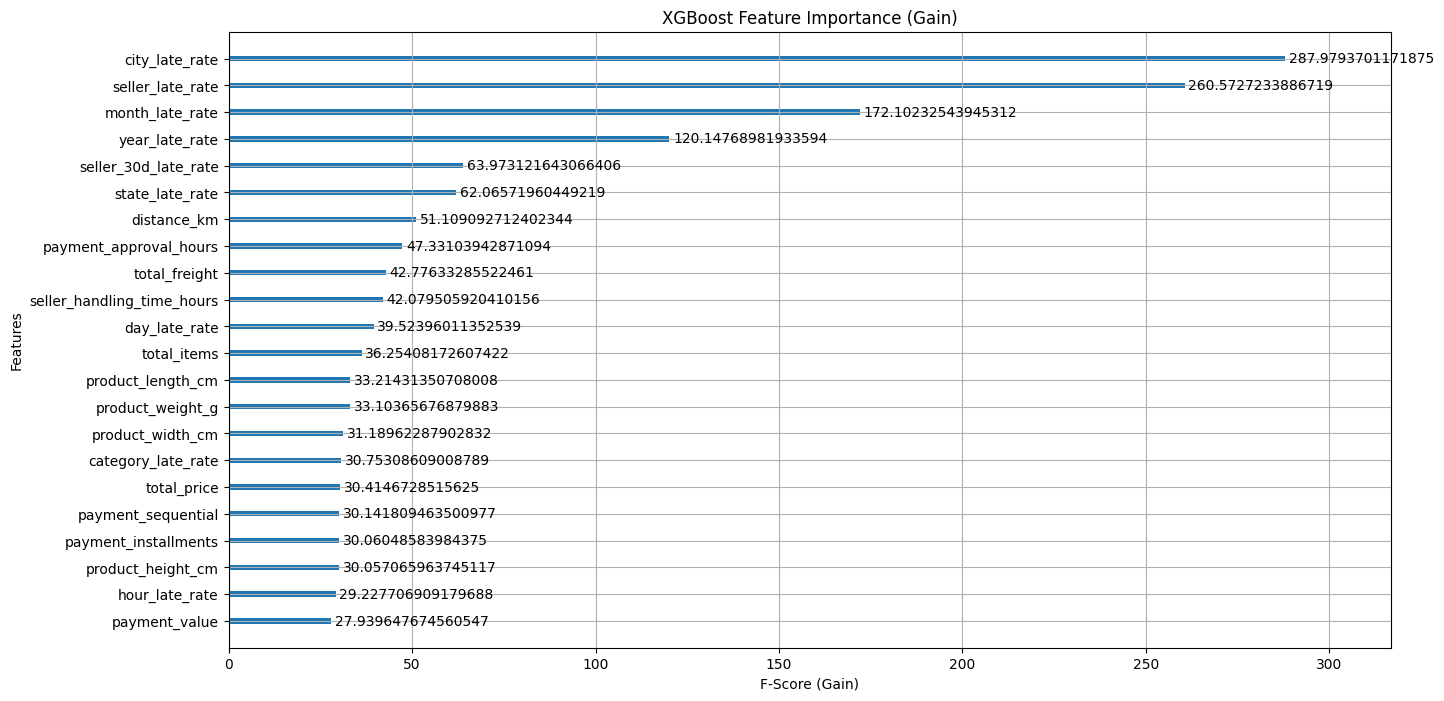

In [28]:
import matplotlib.pyplot as plt
from xgboost import plot_importance

plt.rcParams['figure.figsize'] = (15, 8)

plot_importance(
    XGB_tuned,
    importance_type = 'gain',
    max_num_features = 22,
    title = "XGBoost Feature Importance (Gain)",
    xlabel = "F-Score (Gain)"
)

plt.show()

In [29]:
dead = ['total_freight', 'total_items', 'product_weight_g', 'payment_value', 'product_height_cm', 'category_late_rate', 'product_length_cm', 'hour_late_rate', 'payment_sequential', 'product_width_cm', 'total_price', 'payment_installments', 'payment_type']
df.drop(columns = dead)


majority_class = df[df['label'] == False]
minority_class = df[df['label'] == True]

majority_undersampled = majority_class.sample(n=len(minority_class), random_state=42)

balanced_data = pd.concat([majority_undersampled, minority_class])

X = balanced_data.drop(columns=['label'])
Y = balanced_data['label']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

XGB_balanced = XGBClassifier(
    max_depth=5,
    learning_rate=0.05,
    n_estimators=300,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

XGB_balanced.fit(X_train, Y_train)
Y_prob_balanced = XGB_balanced.predict_proba(X_test)[:,1]

for threshold in np.arange(0.1, 1, 0.05):
    threshold = round(threshold, 2)
    print("Threshold: ", threshold)
    Y_pred_custom = (Y_prob_balanced>=threshold).astype(bool)
    print(classification_report(Y_test, Y_pred_custom), "\n")


Threshold:  0.1
              precision    recall  f1-score   support

       False       0.98      0.27      0.42      1519
        True       0.58      0.99      0.73      1543

    accuracy                           0.63      3062
   macro avg       0.78      0.63      0.58      3062
weighted avg       0.78      0.63      0.58      3062
 

Threshold:  0.15
              precision    recall  f1-score   support

       False       0.94      0.30      0.46      1519
        True       0.59      0.98      0.74      1543

    accuracy                           0.65      3062
   macro avg       0.77      0.64      0.60      3062
weighted avg       0.76      0.65      0.60      3062
 

Threshold:  0.2
              precision    recall  f1-score   support

       False       0.91      0.38      0.54      1519
        True       0.61      0.96      0.75      1543

    accuracy                           0.68      3062
   macro avg       0.76      0.67      0.65      3062
weighted avg       0.

In [30]:
check_df = X_train.copy()
check_df['label'] = Y_train

check_df['distance_rounded'] = check_df['distance_km'].round(0)
check_df['seller_rate_rounded'] = check_df['seller_late_rate'].round(2)

overlap = check_df.groupby(['distance_rounded', 'seller_rate_rounded'])['label'].agg(['mean', 'count'])

conflicts = overlap[(overlap['count'] >= 10) & (overlap['mean'] > 0.2) & (overlap['mean'] < 0.8)]

print(f"Number of highly overlapping feature clusters: {len(conflicts)}")
print(conflicts.head(10))

Number of highly overlapping feature clusters: 5
                                          mean  count
distance_rounded seller_rate_rounded                 
16.0             0.06                 0.400000     10
19.0             0.06                 0.300000     10
20.0             0.06                 0.214286     14
26.0             0.06                 0.384615     13
35.0             0.06                 0.300000     10


In [31]:
df

,total_price,total_freight,total_items,payment_type,payment_sequential,payment_installments,payment_value,label,seller_30d_late_rate,product_weight_g,...,payment_approval_hours,distance_km,seller_late_rate,city_late_rate,state_late_rate,category_late_rate,hour_late_rate,month_late_rate,day_late_rate,year_late_rate
0,895.0,21.02,1,0,1.0,10.0,916.02,False,0.081124,11800.0,...,24.119722,687.431565,0.00000,0.076923,0.049462,0.062810,0.084911,0.051881,0.084468,0.065884
1,895.0,21.02,1,0,1.0,4.0,916.02,False,0.000000,11800.0,...,0.266667,716.237761,0.00000,0.065574,0.056074,0.062810,0.079547,0.050451,0.075391,0.065884
2,895.0,21.02,1,0,1.0,8.0,916.02,False,0.000000,11800.0,...,15.662778,411.866870,0.00000,0.000000,0.056074,0.062810,0.074528,0.050451,0.077949,0.065884
3,99.9,21.15,1,0,1.0,4.0,121.05,False,0.081124,8875.0,...,0.159722,1736.921636,0.06701,0.071429,0.066743,0.080223,0.085002,0.135341,0.075815,0.065884
4,499.5,74.35,5,0,1.0,4.0,573.85,False,0.000000,8875.0,...,1.605278,523.465569,0.06701,0.150000,0.134885,0.080223,0.087715,0.135341,0.075815,0.065884
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94619,109.2,13.34,1,0,1.0,2.0,122.54,False,0.000000,1300.0,...,0.199722,107.159555,0.00000,0.000000,0.058669,0.086704,0.089017,0.061021,0.084468,0.065884
94620,29.4,10.96,1,0,1.0,1.0,40.36,False,0.000000,100.0,...,0.220833,98.075215,0.00000,0.000000,0.058669,0.086704,0.089017,0.061021,0.075391,0.065884
94621,11.5,10.96,1,0,1.0,2.0,22.46,False,0.000000,100.0,...,0.215278,122.626253,0.00000,0.080000,0.058669,0.095907,0.082349,0.061021,0.075815,0.065884
94622,11.5,10.96,1,1,1.0,1.0,22.46,False,0.000000,100.0,...,61.850278,8.003575,0.00000,0.100937,0.058669,0.095907,0.079547,0.061021,0.074906,0.065884


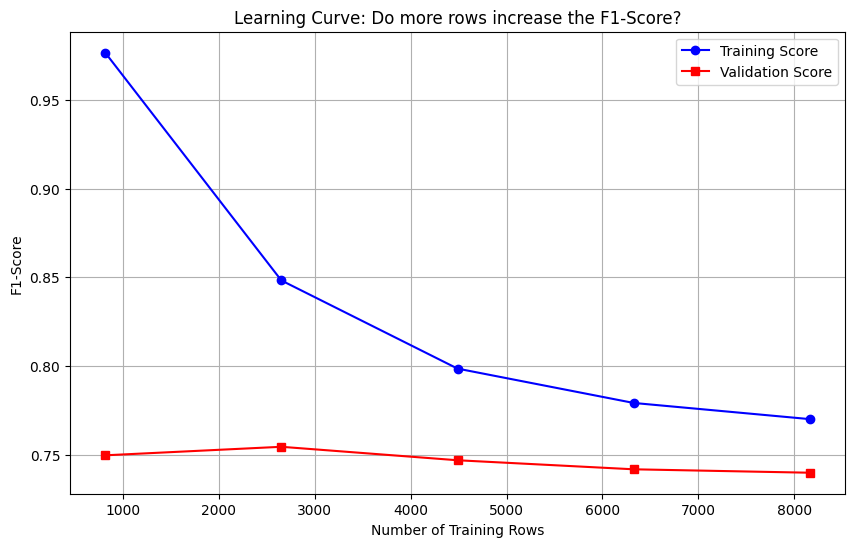

In [32]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
import numpy as np

train_sizes, train_scores, test_scores = learning_curve(
    estimator=XGB_tuned,
    X=X_train, 
    y=Y_train,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=3,
    scoring='f1',
    n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label="Training Score", color="blue", marker='o')
plt.plot(train_sizes, test_mean, label="Validation Score", color="red", marker='s')
plt.title("Learning Curve: Do more rows increase the F1-Score?")
plt.xlabel("Number of Training Rows")
plt.ylabel("F1-Score")
plt.legend(loc="best")
plt.grid(True)
plt.show()

In [33]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) 

dl_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    
    Dense(32, activation='relu'),
    Dropout(0.2),
    
    Dense(1, activation='sigmoid') 
])

dl_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

print("Training Deep Learning Model...")
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = dl_model.fit(
    X_train_scaled, 
    Y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Y_prob_dl = dl_model.predict(X_test_scaled).flatten()

print("\n--- Deep Learning Evaluation ---")
for threshold in np.arange(0.1, 1.0, 0.05):
    clean_threshold = round(threshold, 2)
    print(f"--- Threshold: {clean_threshold} ---")
    
    Y_pred_custom = (Y_prob_dl >= clean_threshold).astype(int)
    print(classification_report(Y_test, Y_pred_custom))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-29 14:08:08.781218: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Training Deep Learning Model...
Epoch 1/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6660 - loss: 0.6022 - val_accuracy: 0.7321 - val_loss: 0.5335
Epoch 2/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7228 - loss: 0.5465 - val_accuracy: 0.7456 - val_loss: 0.5145
Epoch 3/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7290 - loss: 0.5351 - val_accuracy: 0.7456 - val_loss: 0.5088
Epoch 4/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7358 - loss: 0.5284 - val_accuracy: 0.7456 - val_loss: 0.5052
Epoch 5/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7432 - loss: 0.5238 - val_accuracy: 0.7464 - val_loss: 0.5041
Epoch 6/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7424 - loss: 0.5202 - val_accuracy: 0.7460 - val_loss: 0.5000
Epoch 7/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7485 - loss: 0.5143 - val_accuracy: 0.7436 - val_loss: 0.5001
Epoch 8/100
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 